In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
import time
import math

# Distribuição Gamma

## Exercício 1

Gere uma amostra de uma distribuição $\operatorname{Gamma}(k,\lambda)$, com $k$ inteiro, via soma de exponenciais. Verifique seu resultado comparando o histograma da sua distribuição com o de uma amostra gerada via NumPy.

In [2]:
def distribuicao_gama(x, a, b):
    return b**a / math.gamma(a) * x**(a-1) * np.exp(-b*x)   # forma taxa

In [3]:
lbd = 10
n = 50
M = 1_000_000

In [4]:
x = np.linspace(3,8)
fx = distribuicao_gama(x, n, lbd)


In [5]:
U = np.random.uniform(size=(M,n))
exp = (-1)*np.log(U)/lbd
gama = np.sum(exp, axis=1)


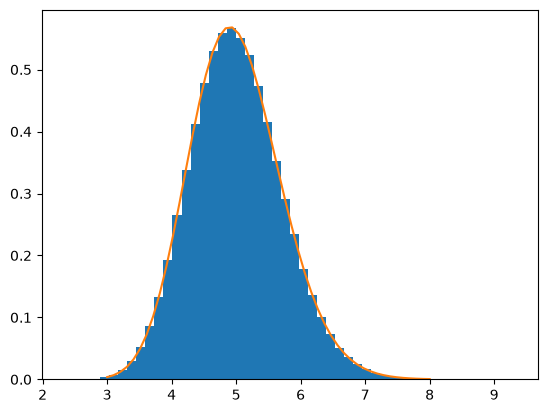

In [6]:
plt.hist(gama, density=True, bins=50)
plt.plot(x,fx)

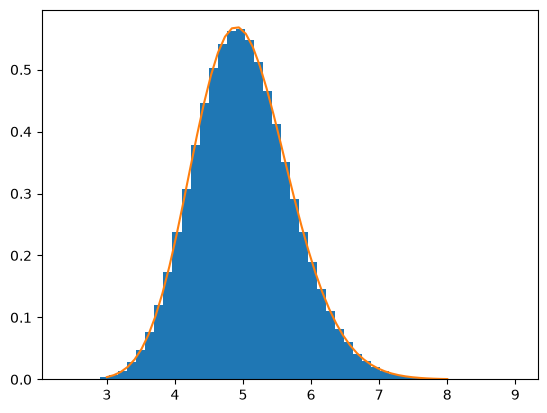

In [7]:
plt.hist(np.random.gamma(n, 1/lbd, size = M), density=True, bins=50)
plt.plot(x,fx)
plt.show()

## Exercício 2

Gere uma amostra de uma distribuição $\operatorname{Gamma}(\alpha,\lambda)$, com $\alpha>1$, via aceitação-rejeição. Verifique seu resultado comparando o histograma da sua distribuição com o de uma amostra gerada via NumPy.

In [8]:
def distribuicao_gama(x, a, b):
    return b**a / math.gamma(a) * x**(a-1) * np.exp(-b*x)   # forma taxa


def densidade_exp(x, lamb=1):
    return lamb*np.exp(-x*lamb)

In [9]:
mi = 3
a = 2.5
lamb = 10 # mi sempre menor q lamb


In [10]:
x_melhor = (a-1)/(lamb-mi)
print(x_melhor)

0.21428571428571427


In [11]:
c = distribuicao_gama(x_melhor, a, lamb) / densidade_exp(x_melhor, mi)
print(c)

1.7550546778864502


In [17]:
M = 10_000
amostras_gama = []
for _ in range(M):
    U = np.random.uniform()
    exp = (-1)*np.log(np.random.uniform())/mi
    while U * c * densidade_exp(exp, mi) > distribuicao_gama(exp, a, lamb):
        U = np.random.uniform()
        exp = (-1)*np.log(np.random.uniform())/mi
    amostras_gama.append(exp)

In [18]:
x = np.linspace(0, 3)
fx = distribuicao_gama(x, a, lamb)

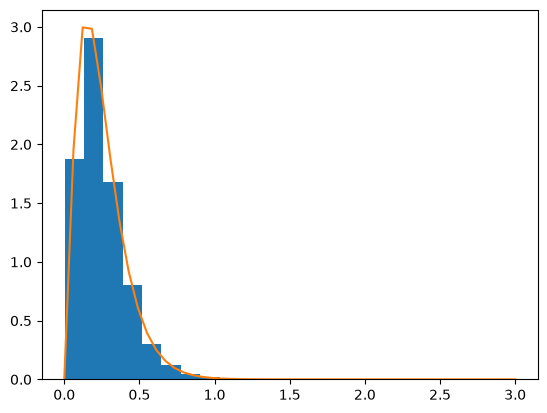

In [19]:
plt.hist(amostras_gama, density= True)
plt.plot(x,fx)

## Exercício 3

Gere uma amostra de uma distribuição $\operatorname{Gamma}(\alpha,\lambda)$, com $\alpha>1$, utilizando a técnica vista em sala, isto é, usando o fato de que, se $G \sim \Gamma(\alpha+1,\lambda)$ e $U \sim \operatorname{Unif}(0,1)$ são independentes, então

$$
X = G U^{1/\alpha} \sim \Gamma(\alpha,\lambda).
$$
Verifique seu resultado comparando o histograma da sua distribuição com o de uma amostra gerada via NumPy.

# Distribuição Beta

## Exercício 4

Gere uma amostra de uma distribuição $\operatorname{Beta}(\alpha,\beta)$, com $\alpha,\beta>1$, via aceitação-rejeição. Verifique seu resultado comparando o histograma da sua distribuição com o de uma amostra gerada via NumPy.

## Exercício 5

Gere uma amostra de uma distribuição $\operatorname{Beta}(\alpha,\beta)$ utilizando o fato de que, se

$$
G_1 \sim \Gamma(\alpha,1), \qquad G_2 \sim \Gamma(\beta,1)
$$

são independentes, então

$$
X = \frac{G_1}{G_1+G_2} \sim \operatorname{Beta}(\alpha,\beta).
$$

Verifique seu resultado comparando o histograma da sua distribuição com o de uma amostra gerada via NumPy.